# Segmentation des anomalies avec U-Net (DSO 1), version 2
**Hasna.** Suite de **seg_unet.ipynb**. Le modèle dit **où** est le danger : pour chaque pixel, est-ce une anomalie (1) ou le fond (0) ?

La version 1 atteint l'objectif sur le test (IoU 0,73, AP 0,92), mais elle apprend par cœur : IoU 0,93 en train contre 0,40 en validation.
**Corrections de cette version :**
1. **Plus de variations aléatoires** sur le train (zoom / recadrage, retournement, couleurs), appliquées à l'image **et** au masque ensemble
2. **Moins de poids entraînés** : seul le dernier bloc de l'encodeur (`layer4`) est dégelé
3. **Vraie tête 1 × 1** (fully connected par pixel) + Dropout

Objectif du DSO 1 : **IoU ≥ 0,5 et AP ≥ 0,6**.

## 0. Installation (une seule fois)

In [3]:
%pip install segmentation-models-pytorch

Note: you may need to restart the kernel to use updated packages.


**Explication :** installe la bibliothèque `segmentation_models_pytorch` (smp), qui contient U-Net avec un encodeur pré-entraîné. À exécuter une seule fois, puis **redémarrer le kernel** (Kernel → Restart).

## 1. Import

In [6]:
import os, time                                   # chemins et mesure du temps
import numpy as np                                # calculs sur les tableaux
import pandas as pd                               # tableaux (etiquettes.csv)
import matplotlib.pyplot as plt                   # graphiques et images
from PIL import Image, ImageEnhance               # ouvrir images et masques ; changer luminosité / contraste / couleurs
import torch                                      # PyTorch
import torch.nn as nn                             # couches (Conv2d, Dropout2d)
import torch.nn.functional as F                   # fonctions de perte (BCE)
from torch.utils.data import Dataset, DataLoader  # lecture des données par paquets
import segmentation_models_pytorch as smp         # U-Net pré-entraîné
from sklearn.metrics import roc_auc_score, average_precision_score   # AUROC et AP au niveau pixel

DOSSIER = r"C:\Users\troud\Desktop\RoadAnomaly"   # dossier principal du projet
if not os.path.isdir(os.path.join(DOSSIER, "frames")):
    DOSSIER = os.path.join(DOSSIER, "RoadAnomaly")
PREP = os.path.join(DOSSIER, "frames", "DataPreparation")   # images et masques préparés

torch.manual_seed(42); np.random.seed(42)                   # résultats reproductibles
device = "cuda" if torch.cuda.is_available() else "cpu"     # GPU s'il existe, sinon CPU
print("Appareil :", device)

Appareil : cpu


**Explication :** on importe les bibliothèques et on indique où se trouve `DataPreparation` (images 512 × 512 et masques 0 / 1). `manual_seed` rend les résultats reproductibles.

## 2. Chargement des données

In [9]:
TAILLE = 256                                      # 256 x 256 : 4 fois plus rapide que 512 sur CPU (mettre 512 sur GPU)
MOYENNE = np.array([0.485, 0.456, 0.406])         # moyenne ImageNet (R, G, B)
ECART = np.array([0.229, 0.224, 0.225])           # écart-type ImageNet
etiquettes = pd.read_csv(f"{PREP}/etiquettes.csv")   # nom et ensemble de chaque image

class SegDataset(Dataset):                        # donne une image et son masque
    def __init__(self, ensemble):
        self.ensemble = ensemble
        self.df = etiquettes[etiquettes.ensemble == ensemble].reset_index(drop=True)   # images de cet ensemble
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        nom = self.df.nom[i]
        img = Image.open(f"{PREP}/{self.ensemble}/images/{nom}.png").convert("RGB")
        masque = Image.open(f"{PREP}/{self.ensemble}/masques/{nom}.png")
        if self.ensemble == "train":                                 # variations aléatoires, train seulement
            cote = int(img.width * np.random.uniform(0.7, 1.0))      # zoom : on garde 70 à 100 % de l'image
            x0, y0 = np.random.randint(0, img.width - cote + 1, 2)   # position au hasard
            boite = (x0, y0, x0 + cote, y0 + cote)
            img, masque = img.crop(boite), masque.crop(boite)        # même recadrage pour l'image ET le masque
            for f in (ImageEnhance.Brightness, ImageEnhance.Contrast, ImageEnhance.Color):
                img = f(img).enhance(np.random.uniform(0.7, 1.3))    # luminosité, contraste, couleurs (image seulement)
        img = img.resize((TAILLE, TAILLE), Image.BILINEAR)
        masque = masque.resize((TAILLE, TAILLE), Image.NEAREST)      # NEAREST : garde 0 / 1
        img = (np.array(img) / 255.0 - MOYENNE) / ECART              # pixels 0..1 puis normalisation ImageNet
        masque = np.array(masque, dtype=np.float32)                  # 0 = fond, 1 = anomalie
        if self.ensemble == "train" and np.random.rand() < 0.5:      # train : 1 fois sur 2...
            img, masque = img[:, ::-1], masque[:, ::-1]              # ...retourne image ET masque ensemble
        img = torch.tensor(img.transpose(2, 0, 1).copy(), dtype=torch.float32)   # format PyTorch : canaux, hauteur, largeur
        masque = torch.tensor(masque.copy()).unsqueeze(0)            # 1 canal
        return img, masque

train_ds, val_ds, test_ds = SegDataset("train"), SegDataset("val"), SegDataset("test")
train_dl = DataLoader(train_ds, batch_size=8, shuffle=True)   # paquets de 8 images, mélangés
val_dl = DataLoader(val_ds, batch_size=8)
test_dl = DataLoader(test_ds, batch_size=8)
print(len(train_ds), "images train,", len(val_ds), "val,", len(test_ds), "test")

698 images train, 139 val, 163 test


**Explication :** le `Dataset` lit chaque image et son masque, les met en **256 × 256** (image avec `BILINEAR`, masque avec `NEAREST` pour garder seulement 0 et 1) et normalise l'image comme ImageNet. Pour le **train seulement**, chaque image change à chaque époque : on garde une zone au hasard de 70 à 100 % de l'image (zoom), on change luminosité, contraste et couleurs, et on la retourne une fois sur deux. Le recadrage et le retournement sont appliqués **au masque aussi**, pour qu'il reste aligné ; les couleurs ne touchent que l'image. Le modèle ne voit donc jamais deux fois la même image, ce qui l'empêche d'apprendre par cœur. Batch = **8**, car une image de segmentation demande beaucoup de mémoire. Sur GPU (Colab), on peut mettre `TAILLE = 512`.

## 3. Visualisation

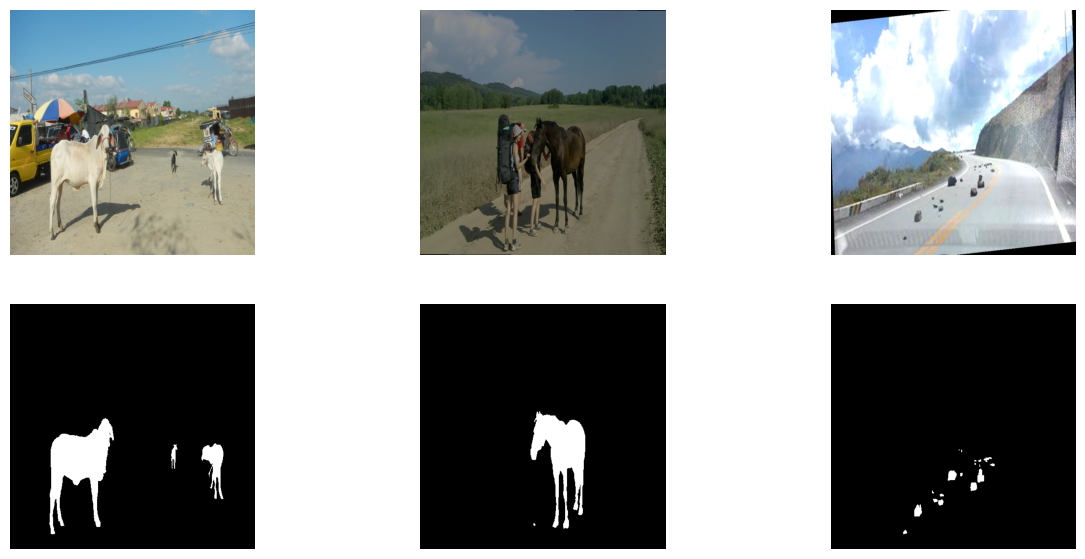

In [12]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for j in range(3):
    nom = train_ds.df.nom[j * 200]                                      # 3 images différentes du train
    ax[0, j].imshow(Image.open(f"{PREP}/train/images/{nom}.png"))     # image
    ax[1, j].imshow(Image.open(f"{PREP}/train/masques/{nom}.png"), cmap="gray")   # masque : blanc = anomalie
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.show()

**Explication :** en haut les images, en bas leurs masques (blanc = anomalie). C'est exactement ce que le modèle doit apprendre à dessiner.

## 4. Création du modèle

In [15]:
model = smp.Unet("resnet34", encoder_weights="imagenet", classes=1)   # U-Net, encodeur ResNet-34 pré-entraîné ImageNet, 1 canal de sortie
model.segmentation_head = nn.Sequential(                              # nouvelle tête à la place de la conv 3 x 3 d'origine
    nn.Dropout2d(0.2),                                                # éteint 20 % des cartes au hasard (contre l'apprentissage par cœur)
    nn.Conv2d(16, 1, kernel_size=1),                                  # conv 1 x 1 = fully connected appliquée à chaque pixel
)
model = model.to(device)                                              # sur GPU ou CPU
print(model)                                                          # toute l'architecture

Unet(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05,

**Explication :** U-Net a deux parties. L'**encodeur** (ResNet-34 pré-entraîné ImageNet) réduit l'image pour comprendre **ce qu'il y a**. Le **décodeur** la ré-agrandit pour retrouver **où c'est**. Les **skip connections** relient les deux côtés pour garder les détails fins (pattes d'un animal, bords d'un cône). `classes=1` : une seule sortie, la probabilité d'anomalie de chaque pixel. On remplace la tête d'origine (une conv 3 × 3) par une **conv 1 × 1** précédée d'un **Dropout**, pour respecter l'étape « Fully Connected » de l'architecture imposée et limiter l'apprentissage par cœur.

## 5. Architecture

In [18]:
couches = pd.Series([type(m).__name__ for m in model.modules()]).value_counts()   # compte chaque type de couche
print(couches.reindex(["Conv2d", "ReLU", "MaxPool2d"]).fillna(0).astype(int))     # convolution, activation, pooling
print("Tête :", model.segmentation_head)                                         # Dropout + conv 1 x 1 finale
print("Paramètres :", round(sum(p.numel() for p in model.parameters()) / 1e6, 1), "millions")

Conv2d       47
ReLU         27
MaxPool2d     1
Name: count, dtype: int32
Tête : Sequential(
  (0): Dropout2d(p=0.2, inplace=False)
  (1): Conv2d(16, 1, kernel_size=(1, 1), stride=(1, 1))
)
Paramètres : 24.4 millions


**Explication :** on retrouve l'architecture imposée dans U-Net :

| Étape imposée | Dans U-Net |
| --- | --- |
| 1. Convolution | `Conv2d` 3 × 3 de l'encodeur ResNet-34 et du décodeur |
| 2. Activation | `ReLU` après chaque convolution (Conv → BatchNorm → ReLU) |
| 3. Pooling | `MaxPool2d` et convolutions de pas 2 dans l'encodeur : l'image passe de 256 à 8 pixels de côté |
| 4. Fully Connected | `segmentation_head` : Dropout + conv **1 × 1**, c'est-à-dire une couche fully connected appliquée à **chaque pixel** |
| 5. Output | 1 canal + **Sigmoid** → probabilité d'anomalie de chaque pixel |

En segmentation, une vraie couche `Linear` détruirait la position des pixels. La conv 1 × 1 fait le même calcul qu'une couche fully connected, mais pixel par pixel.

## 6. Perte et optimiseur

In [21]:
def dice_focal(logits, masque, alpha=0.75, gamma=2):        # perte de DataAugmentation.ipynb
    prob = torch.sigmoid(logits)                             # probabilité d'anomalie par pixel
    dice = 1 - (2 * (prob * masque).sum() + 1) / (prob.sum() + masque.sum() + 1)   # 1 - recouvrement prédiction / vrai masque
    bce = F.binary_cross_entropy_with_logits(logits, masque, reduction="none")    # erreur pixel par pixel
    pt = torch.exp(-bce)                                     # proche de 1 = pixel facile
    a = alpha * masque + (1 - alpha) * (1 - masque)          # plus de poids aux pixels anomalie
    focal = (a * (1 - pt) ** gamma * bce).mean()             # réduit le poids des pixels faciles (la route)
    return dice + focal

def passage(model, dl, optimiseur=None):                     # un passage sur un ensemble ; avec optimiseur = entraînement
    entrainement = optimiseur is not None
    model.train(entrainement)                                # mode entraînement ou évaluation
    perte_tot, inter, union, somme = 0, 0, 0, 0
    with torch.set_grad_enabled(entrainement):               # gradients seulement pendant l'entraînement
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            logits = model(x)                                # prédiction (avant Sigmoid)
            perte = dice_focal(logits, y)
            if entrainement:
                optimiseur.zero_grad(); perte.backward(); optimiseur.step()   # corrige les poids
            pred = (torch.sigmoid(logits) > 0.5).float()     # pixel = anomalie si probabilité > 0,5
            inter += (pred * y).sum().item()                 # pixels anomalie bien trouvés
            union += ((pred + y) > 0).sum().item()           # pixels anomalie prédits OU vrais
            somme += pred.sum().item() + y.sum().item()
            perte_tot += perte.item() * len(y)
    return perte_tot / len(dl.dataset), inter / max(union, 1), 2 * inter / max(somme, 1)   # perte, IoU, Dice

**Explication :** la perte **Dice + Focal** (expliquée dans DataAugmentation.ipynb) règle le déséquilibre : il y a environ 90 % de pixels de fond. La Dice mesure le recouvrement avec le vrai masque, la Focal se concentre sur les pixels difficiles. `passage` parcourt un ensemble : avec un optimiseur il entraîne, sans optimiseur il mesure seulement. Il renvoie la perte, l'**IoU** (pixels communs / pixels réunis) et le **Dice**.

## 7. Entraînement 1 : encodeur gelé

In [24]:
for p in model.encoder.parameters():
    p.requires_grad = False                    # encodeur gelé : ses poids ImageNet ne bougent pas
optimiseur = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-3, weight_decay=0.01)   # décodeur + tête

historique = []
for epoque in range(5):
    debut = time.time()
    perte_train, iou_train, _ = passage(model, train_dl, optimiseur)   # apprend
    perte_val, iou_val, _ = passage(model, val_dl)                     # mesure
    historique.append({"perte_train": perte_train, "perte_val": perte_val, "iou_train": iou_train, "iou_val": iou_val})
    print(f"Époque {epoque + 1} : perte {perte_train:.3f} / {perte_val:.3f}   IoU {iou_train:.2f} / {iou_val:.2f}   ({time.time() - debut:.0f} s)")

Époque 1 : perte 0.696 / 0.857   IoU 0.43 / 0.26   (130 s)
Époque 2 : perte 0.570 / 0.783   IoU 0.67 / 0.39   (122 s)
Époque 3 : perte 0.464 / 0.731   IoU 0.73 / 0.39   (123 s)
Époque 4 : perte 0.345 / 0.696   IoU 0.81 / 0.35   (125 s)
Époque 5 : perte 0.258 / 0.654   IoU 0.82 / 0.36   (344 s)


**Explication :** l'encodeur est gelé : seuls le décodeur et la tête apprennent, pendant 5 époques (lr = 0,001). Chaque ligne affiche train / validation et la durée de l'époque. Sur CPU, compte plusieurs minutes par époque.

## 8. Entraînement 2 : dernier bloc de l'encodeur + early stopping

In [27]:
for p in model.encoder.layer4.parameters():
    p.requires_grad = True                     # on dégèle seulement layer4, le dernier bloc de l'encodeur
optimiseur = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-4, weight_decay=0.01)   # lr 10 fois plus petit
print("Paramètres entraînés :", round(sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6, 1), "millions")

meilleur_iou, attente, PATIENCE = 0, 0, 5
for epoque in range(30):                       # 30 époques maximum
    debut = time.time()
    perte_train, iou_train, _ = passage(model, train_dl, optimiseur)
    perte_val, iou_val, _ = passage(model, val_dl)
    historique.append({"perte_train": perte_train, "perte_val": perte_val, "iou_train": iou_train, "iou_val": iou_val})
    print(f"Époque {epoque + 1} : perte {perte_train:.3f} / {perte_val:.3f}   IoU {iou_train:.2f} / {iou_val:.2f}   ({time.time() - debut:.0f} s)")
    if iou_val > meilleur_iou:                 # meilleure IoU de validation ?
        meilleur_iou, attente = iou_val, 0
        torch.save(model.state_dict(), "unet_v2_meilleur.pt")   # sauvegarde le meilleur modèle
    else:
        attente += 1
        if attente == PATIENCE:                # 5 époques sans progrès : early stopping
            print("Early stopping : l'IoU de validation ne progresse plus")
            break
print("Meilleure IoU de validation :", round(meilleur_iou, 3))

Paramètres entraînés : 16.3 millions
Époque 1 : perte 0.207 / 0.515   IoU 0.87 / 0.50   (405 s)
Époque 2 : perte 0.197 / 0.492   IoU 0.89 / 0.51   (322 s)
Époque 3 : perte 0.187 / 0.529   IoU 0.89 / 0.45   (142 s)
Époque 4 : perte 0.183 / 0.539   IoU 0.90 / 0.44   (136 s)
Époque 5 : perte 0.169 / 0.536   IoU 0.90 / 0.43   (136 s)
Époque 6 : perte 0.157 / 0.495   IoU 0.90 / 0.47   (135 s)
Époque 7 : perte 0.161 / 0.422   IoU 0.91 / 0.57   (157 s)
Époque 8 : perte 0.148 / 0.394   IoU 0.92 / 0.59   (130 s)
Époque 9 : perte 0.142 / 0.426   IoU 0.92 / 0.55   (129 s)
Époque 10 : perte 0.140 / 0.413   IoU 0.92 / 0.57   (130 s)
Époque 11 : perte 0.133 / 0.404   IoU 0.92 / 0.54   (129 s)
Époque 12 : perte 0.134 / 0.405   IoU 0.92 / 0.53   (127 s)
Époque 13 : perte 0.121 / 0.362   IoU 0.93 / 0.59   (127 s)
Early stopping : l'IoU de validation ne progresse plus
Meilleure IoU de validation : 0.592


**Explication :** dans la version 1 on dégelait tout l'encodeur, ce qui laissait beaucoup de poids libres pour apprendre par cœur. Ici on dégèle seulement **layer4**, le dernier bloc de l'encodeur (formes complexes), avec un lr 10 fois plus petit (0,0001). Les premiers blocs (bords, textures) gardent leurs poids ImageNet. On sauvegarde le modèle chaque fois que l'**IoU de validation** s'améliore, et on arrête après 5 époques sans progrès (**early stopping**).

## 9. Courbes

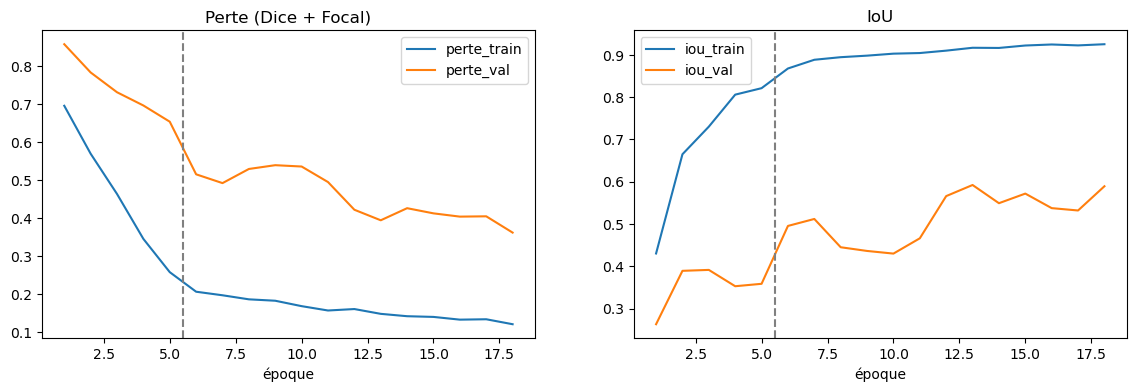

In [30]:
h = pd.DataFrame(historique); h.index = h.index + 1
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
h[["perte_train", "perte_val"]].plot(ax=ax[0], title="Perte (Dice + Focal)")
h[["iou_train", "iou_val"]].plot(ax=ax[1], title="IoU")
for a in ax:
    a.axvline(5.5, color="gray", linestyle="--")    # fin de l'entraînement 1
    a.set_xlabel("époque")
plt.show()

**Explication :** perte et IoU en train et en validation. Pas d'overfitting si la perte de validation descend avec celle du train et si l'écart d'IoU entre train et validation reste petit.

## 10. Validation / test

In [33]:
model.load_state_dict(torch.load("unet_v2_meilleur.pt", map_location=device))   # recharge le meilleur modèle

@torch.no_grad()
def probabilites(model, dl):                                  # probabilités et vrais pixels (1 pixel sur 16)
    model.eval(); P, Y = [], []
    for x, y in dl:
        P.append(torch.sigmoid(model(x.to(device))).cpu().numpy().ravel()[::16])
        Y.append(y.numpy().ravel()[::16])
    return np.concatenate(P), np.concatenate(Y)

for nom, dl in [("Validation", val_dl), ("Test", test_dl)]:
    _, iou, dice = passage(model, dl)                         # IoU et Dice (seuil 0,5)
    p, y = probabilites(model, dl)
    print(f"{nom} : IoU = {iou:.2f}   Dice = {dice:.2f}   AUROC = {roc_auc_score(y, p):.3f}   AP = {average_precision_score(y, p):.3f}")

Validation : IoU = 0.59   Dice = 0.74   AUROC = 0.937   AP = 0.764
Test : IoU = 0.78   Dice = 0.88   AUROC = 0.987   AP = 0.943


**Explication :** on recharge le meilleur modèle et on le mesure sur la validation puis, une seule fois, sur le test. **IoU** et **Dice** mesurent le recouvrement avec le vrai masque (seuil 0,5). **AUROC** et **AP** mesurent la qualité des probabilités sans choisir de seuil ; ce sont les métriques standard du dataset RoadAnomaly. On prend 1 pixel sur 16 pour aller plus vite, le résultat est presque identique. Objectif du DSO 1 : **IoU ≥ 0,5 et AP ≥ 0,6**.

## 11. Exemples : meilleures et pires prédictions

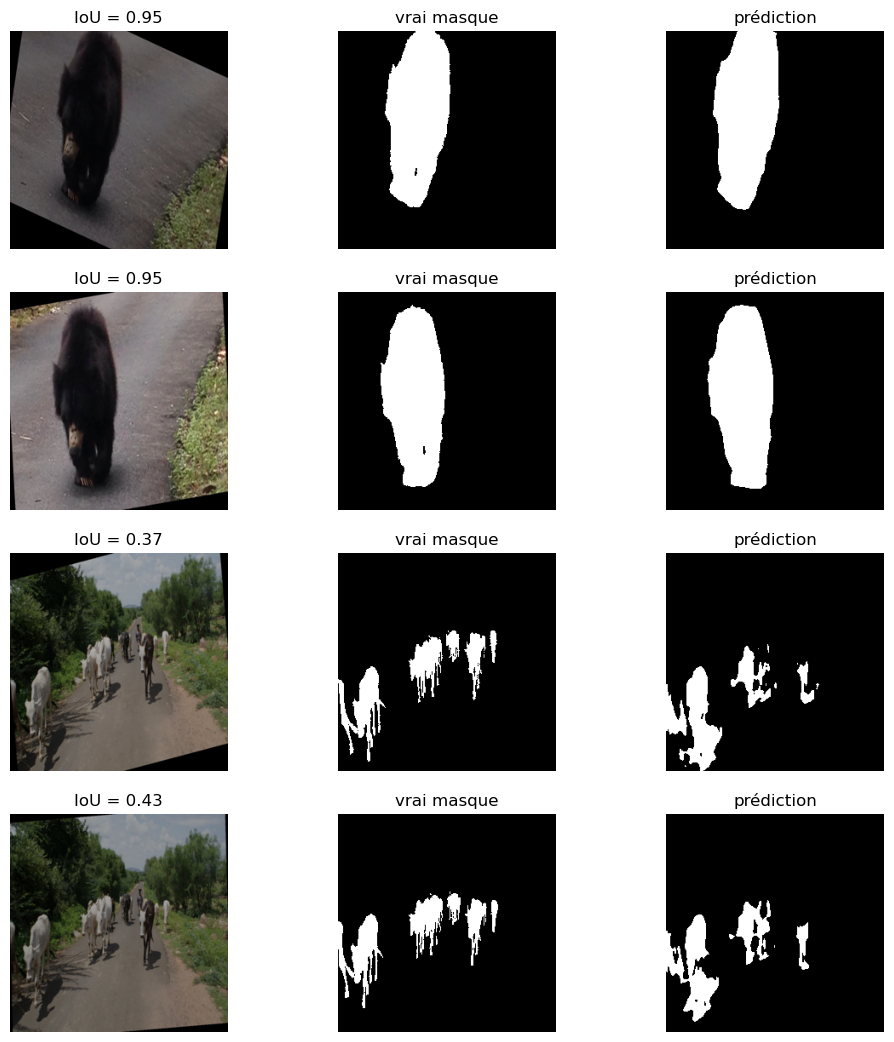

In [36]:
model.eval(); scores = []
with torch.no_grad():
    for i in range(len(test_ds)):
        x, y = test_ds[i]
        pred = (torch.sigmoid(model(x.unsqueeze(0).to(device))) > 0.5).float().cpu()[0]
        scores.append(((pred * y).sum() / (((pred + y) > 0).sum() + 1e-6)).item())   # IoU de cette image
ordre = np.argsort(scores)                                    # du pire au meilleur
fig, ax = plt.subplots(4, 3, figsize=(12, 13))
for ligne, i in enumerate(list(ordre[-2:]) + list(ordre[:2])):   # 2 meilleures puis 2 pires
    x, y = test_ds[i]
    pred = (torch.sigmoid(model(x.unsqueeze(0).to(device))) > 0.5).float().cpu()[0, 0]
    ax[ligne, 0].imshow(Image.open(f"{PREP}/test/images/{test_ds.df.nom[i]}.png").resize((TAILLE, TAILLE)))
    ax[ligne, 1].imshow(y[0], cmap="gray"); ax[ligne, 2].imshow(pred, cmap="gray")
    ax[ligne, 0].set_title(f"IoU = {scores[i]:.2f}"); ax[ligne, 1].set_title("vrai masque"); ax[ligne, 2].set_title("prédiction")
    for a in ax[ligne]: a.axis("off")
plt.show()

**Explication :** on calcule l'IoU de chaque image du test, puis on affiche les 2 meilleures et les 2 pires : image, vrai masque, masque prédit. Cela montre où le modèle réussit (gros objets bien contrastés) et où il se trompe (petits objets comme les cônes, objets qui ressemblent à la route).

## 12. Comparaison avec la version 1

In [39]:
_, iou_val, _ = passage(model, val_dl)                   # IoU de la version 2
_, iou_test, _ = passage(model, test_dl)
pd.DataFrame({
    "Version 1": [0.93, 0.40, 0.73],                     # scores copiés de seg_unet.ipynb
    "Version 2": [round(historique[-1]["iou_train"], 2), round(iou_val, 2), round(iou_test, 2)],
}, index=["IoU train (dernière époque)", "IoU validation", "IoU test"])

,Version 1,Version 2
IoU train (dernière époque),0.93,0.93
IoU validation,0.40,0.59
IoU test,0.73,0.78


**Explication :** on compare les deux versions. L'apprentissage par cœur a diminué si **l'écart entre l'IoU du train et celle de la validation est plus petit**. L'IoU du train peut baisser un peu : c'est normal, les images du train sont maintenant plus difficiles à cause des variations aléatoires. On garde la version qui a la **meilleure IoU de validation**.

## Conclusion
- U-Net avec encodeur ResNet-34 pré-entraîné ImageNet : Convolution → ReLU → Pooling → conv 1 × 1 (fully connected par pixel) → Sigmoid
- Perte **Dice + Focal** contre le déséquilibre des pixels (≈ 10 % d'anomalie)
- Contre l'apprentissage par cœur : variations aléatoires (zoom, couleurs, retournement), seul `layer4` dégelé, Dropout dans la tête
- Entraînement en 2 temps : encodeur gelé, puis dernier bloc avec early stopping sur l'IoU de validation
- À comparer avec la version 1 : IoU validation 0,40 / test 0,73, AP validation 0,54 / test 0,92
- Scores à reporter dans le tableau de comparaison : IoU, Dice, AUROC et AP sur le test, objectif atteint ou non
- Le meilleur modèle `unet_v2_meilleur.pt` pourra fournir les masques pour recadrer les images du DSO 2